In [35]:
import emcee
import corner
import pandas as pd
from matplotlib import pyplot as plt
import numpy as np
import pickle
from uncertainties import ufloat
from uncertainties.umath import *
from uncertainties import unumpy as unp
from astropy import units as u
from astropy.cosmology import FlatLambdaCDM
cosmo=FlatLambdaCDM(70, 0.3)
from statistics_functions import chi_squared
from load_data_and_var import generate_nfws_from_combined_dataset_werr

In [36]:
with open('data/mcxc_psz_combined.pkl', 'rb') as f:
    combined_data = pickle.load(f)
low_z_data = combined_data[combined_data['z_y'] < 0.2][combined_data['Sub-Cat']=='REFLEX'][['OName','AName', 'L500', 'z_y']].rename(columns={'AName': 'Name'}).dropna()

/var/folders/99/vfh56jrs1nqcj8zqtcs5fkv40000gn/T/ipykernel_23094/3620387234.py:3: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  low_z_data = combined_data[combined_data['z_y'] < 0.2][combined_data['Sub-Cat']=='REFLEX'][['OName','AName', 'L500', 'z_y']].rename(columns={'AName': 'Name'}).dropna()


In [37]:
low_z_data

,OName,Name,L500,z_y
2,RXCJ0003.8+0203,A2700,0.846881,0.0924
3,RXCJ0006.0-3443,A2721,1.809494,0.1147
6,RXCJ0011.3-2851,A2734,1.086002,0.0620
9,RXCJ0013.6-1930,A0013,1.236332,0.0940
10,RXCJ0014.3-6604,A2746,2.827248,0.1599
...,...,...,...,...
541,RXCJ2344.2-0422,,1.852614,0.0786
543,RXCJ2347.7-2808,A4038,1.029501,0.0300
547,RXCJ2354.2-1024,A2670,1.336537,0.0765
549,RXCJ2357.0-3445,A4059,1.629622,0.0475


In [38]:
reflex_data = pd.read_csv('data/reflex70.txt', header=7, sep='|', skiprows=[range(6), 8],on_bad_lines='warn', skipfooter=1, skipinitialspace=True).rename(columns=lambda x: x.strip())
#data = data.apply(lambda x: x.str.strip() if x.dtype == 'object' else x)
#data['Name'].values.strip()
reflex_data = reflex_data.apply(lambda x: x.str.strip() if x.dtype == 'object' else x)[['RXC', 'Flux', 'e_Flux', 'ObsLum', 'LumCor', 'z']].dropna()

/var/folders/99/vfh56jrs1nqcj8zqtcs5fkv40000gn/T/ipykernel_23094/2434024660.py:1: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support skipfooter; you can avoid this warning by specifying engine='python'.
  reflex_data = pd.read_csv('data/reflex70.txt', header=7, sep='|', skiprows=[range(6), 8],on_bad_lines='warn', skipfooter=1, skipinitialspace=True).rename(columns=lambda x: x.strip())


In [39]:
reflex_data.head()

,RXC,Flux,e_Flux,ObsLum,LumCor,z
0,RXCJ0003.1-0605,4.497,12.4,6.395,6.876,0.2320
1,RXCJ0003.2-3555,7.537,17.8,0.421,0.478,0.0490
2,RXCJ0003.8+0203,4.155,18.8,0.855,0.929,0.0924
3,RXCJ0006.0-3443,5.832,13.6,1.875,1.995,0.1147
4,RXCJ0011.3-2851,12.014,9.0,1.089,1.197,0.0620


In [40]:
comb = pd.merge(low_z_data, reflex_data, left_on='OName', right_on='RXC', how='inner', sort=True)

In [41]:
comb

,OName,Name,L500,z_y,RXC,Flux,e_Flux,ObsLum,LumCor,z
0,RXCJ0003.8+0203,A2700,0.846881,0.0924,RXCJ0003.8+0203,4.155,18.8,0.855,0.929,0.0924
1,RXCJ0006.0-3443,A2721,1.809494,0.1147,RXCJ0006.0-3443,5.832,13.6,1.875,1.995,0.1147
2,RXCJ0011.3-2851,A2734,1.086002,0.0620,RXCJ0011.3-2851,12.014,9.0,1.089,1.197,0.0620
3,RXCJ0013.6-1930,A0013,1.236332,0.0940,RXCJ0013.6-1930,6.071,11.3,1.285,1.353,0.0940
4,RXCJ0014.3-6604,A2746,2.827248,0.1599,RXCJ0014.3-6604,4.485,13.8,2.907,3.160,0.1599
...,...,...,...,...,...,...,...,...,...,...
168,RXCJ2344.2-0422,,1.852614,0.0786,RXCJ2344.2-0422,12.638,7.4,1.855,2.061,0.0786
169,RXCJ2347.7-2808,A4038,1.029501,0.0300,RXCJ2347.7-2808,49.578,3.8,1.014,1.127,0.0300
170,RXCJ2354.2-1024,A2670,1.336537,0.0765,RXCJ2354.2-1024,9.622,12.1,1.337,1.469,0.0765
171,RXCJ2357.0-3445,A4059,1.629622,0.0475,RXCJ2357.0-3445,32.663,5.5,1.698,1.787,0.0475


In [42]:
ONames = (comb['OName'].tolist())

In [43]:
# calculate flux with variance in watts
flux_arr=comb['Flux'].to_numpy()*1e-15 # to get in watts
eflux_arr=comb['e_Flux'].to_numpy()
flux_var=np.array([ufloat(flux_arr[i],eflux_arr[i]*flux_arr[i]/100) for i in range(len(flux_arr))])

In [44]:
# Calculate Lobs from flux with variance

d_L = cosmo.comoving_distance(comb['z_y']).to(u.m).value #(return meters)
#originally in units u.W*1e-15/u.m**2 * Mpc**2
Lobs_calc=(flux_var*4*np.pi*d_L**2) * 1e-37 

#Lobs_calc #now in units of 1e37 W
Lobs_err = [L.std_dev for L in Lobs_calc]
#Lobs_err
Lobs_calc

array([0.745922576900713+/-0.14023344445733404,
       1.5962288643873468+/-0.21708712555667914,
       0.9850814005299323+/-0.0886573260476939,
       1.1271051139128871+/-0.12736287787215625,
       2.333867767423409+/-0.3220737519044305,
       2.4135326772236376+/-0.2920374539440601,
       0.45618706030144873+/-0.04425014484924054,
       1.8425238329482687+/-0.3150715754341539,
       1.2636774736720755+/-0.16806910399838607,
       1.2026954179964795+/-0.09501293802172188,
       4.890977692536981+/-0.1565112861611834,
       2.3879872138694673+/-0.2340227469592078,
       1.4123668858975584+/-0.0748554449525706,
       1.3174099397720227+/-0.08826646596472552,
       0.4175108555327666+/-0.04091606384221112,
       0.17222891932443235+/-0.01377831354595459,
       0.45404892283675474+/-0.042226549823818196,
       0.7175482809428992+/-0.05668631419448903,
       1.7091148865220904+/-0.27345838184353455,
       3.1578969342457186+/-0.42315818918892634,
       1.4289856888365742+

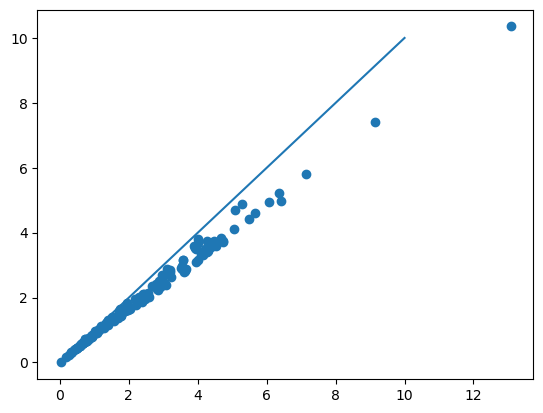

In [45]:
plt.scatter(comb['ObsLum'], [L.nominal_value for L in Lobs_calc])
plt.plot([0,10], [0,10])

In [46]:
# MCMC: L_o=(L_c - b)/m 
# change to L_o=(L500-b)/m
L_obs_data = comb['ObsLum']
L_obs_var=[L.std_dev for L in Lobs_calc]
#L_cor=comb['LumCor']
L500=comb['L500']

Text(0, 0.5, 'L500')

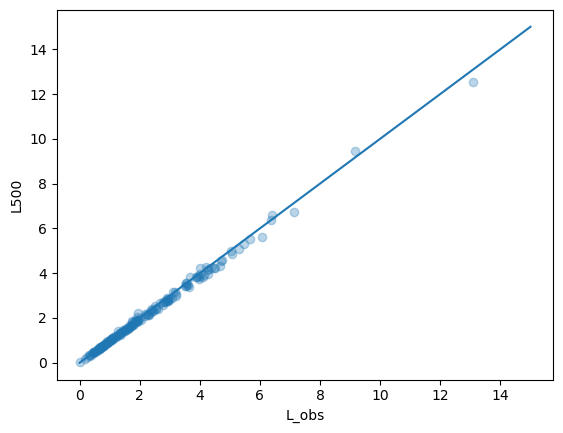

In [47]:
plt.scatter(L_obs_data, L500, alpha=0.3)
plt.plot(np.linspace(0,15), np.linspace(0,15))
plt.xlabel('L_obs')
plt.ylabel('L500')

In [48]:
def log_lik(p0, L_c, obs, var):
    m=p0[0]
    if np.abs(m)<0.00001:
        return -np.inf
    b=p0[1]
    if np.abs(m)>10 or np.abs(b)>10:
        return -np.inf
    pred=(L_c-b)/m
    return -1*chi_squared(pred, obs, var)/2

In [49]:
p0=[1, 0]
log_lik(p0, L500, L_obs_data, np.array(L_obs_var))

-23.439121240851986

In [50]:
ndim=2
nwalkers = 32
guess=(1, 0)
p0 = guess+np.random.normal(scale=0.1, size=(nwalkers, ndim))
p0

array([[ 0.9731447 ,  0.16393446],
       [ 1.15100191,  0.00288614],
       [ 1.07456139,  0.08928817],
       [ 1.21837982, -0.05570259],
       [ 1.03835209,  0.07594261],
       [ 0.86510304, -0.05206133],
       [ 1.23748534, -0.04014336],
       [ 0.98334431, -0.06263223],
       [ 1.00150417, -0.18987667],
       [ 0.99954959,  0.01548103],
       [ 1.23087354,  0.02727612],
       [ 0.94524247,  0.01801018],
       [ 1.03748029, -0.04029135],
       [ 1.16463909, -0.13244039],
       [ 1.13209632, -0.09257765],
       [ 0.90253476, -0.00796787],
       [ 0.96955888,  0.05459768],
       [ 1.03844064, -0.09552824],
       [ 1.07231208, -0.01873366],
       [ 0.97902469, -0.04978988],
       [ 0.91538267,  0.00285634],
       [ 0.93402938, -0.05476456],
       [ 1.06161456,  0.11274995],
       [ 0.87034034,  0.1267698 ],
       [ 1.03136522, -0.27608532],
       [ 1.08426681, -0.21657603],
       [ 1.06869149, -0.09992645],
       [ 0.88281383, -0.08188499],
       [ 1.03194159,

In [51]:
sampler = emcee.EnsembleSampler(nwalkers, ndim, log_lik, args=[L500, L_obs_data, np.array(L_obs_var)])

In [52]:
state = sampler.run_mcmc(p0, 100, progress=True)
sampler.reset()

100%|█████████████████████████████████████████| 100/100 [00:01<00:00, 89.63it/s]


In [53]:
sampler.run_mcmc(state, 5000, progress=True)

100%|███████████████████████████████████████| 5000/5000 [00:57<00:00, 87.25it/s]


State([[ 9.65332731e-01  1.08846837e-02]
 [ 9.77907611e-01  3.63227728e-03]
 [ 9.66760877e-01  9.52069508e-03]
 [ 9.78967662e-01  2.25353556e-03]
 [ 9.85194072e-01 -2.79388294e-03]
 [ 9.70217501e-01  7.65522381e-03]
 [ 9.60668920e-01  2.03772639e-02]
 [ 9.75471819e-01  8.70530842e-04]
 [ 9.86737185e-01 -1.56202522e-04]
 [ 9.76576344e-01  3.34571668e-03]
 [ 9.68524710e-01  1.94265761e-02]
 [ 9.74443865e-01  8.12851460e-03]
 [ 9.89986526e-01 -4.85879170e-03]
 [ 9.76378843e-01  4.95016093e-03]
 [ 9.78271636e-01  2.20966062e-03]
 [ 9.81792708e-01  4.22939382e-04]
 [ 9.80750176e-01  1.02359218e-02]
 [ 9.71846170e-01  4.43339926e-03]
 [ 9.82290046e-01  1.72807991e-03]
 [ 9.71414035e-01  1.33519292e-02]
 [ 9.78128366e-01  2.49223781e-03]
 [ 9.80009195e-01  5.72278623e-03]
 [ 9.86358302e-01  2.57928927e-03]
 [ 9.68268469e-01  7.20578758e-03]
 [ 9.62509733e-01  1.77317985e-02]
 [ 9.74358734e-01  6.16449375e-03]
 [ 9.65161777e-01  1.33540667e-02]
 [ 9.83586554e-01 -4.15185475e-03]
 [ 9.78045636e

In [54]:
flat_samples = sampler.get_chain(flat=True)
print(flat_samples.shape)

(160000, 2)


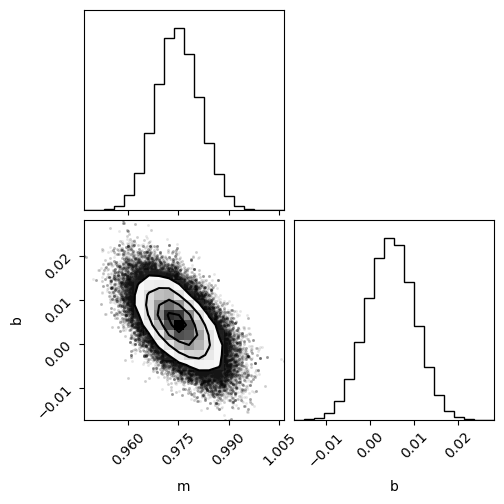

In [55]:
fig = corner.corner(flat_samples, labels=['m', 'b']) 

In [56]:
tau = sampler.get_autocorr_time()
print(tau)

[29.5993864  32.30828731]


In [57]:
np.median(flat_samples[:,0]), np.median(flat_samples[:,1])

(0.9748314817688577, 0.004721150462597585)

In [58]:
m_err=np.var(flat_samples[:,0]) # var=mean((p-pmean)**2)
m_err

4.270760165422667e-05

In [59]:
b_err=np.var(flat_samples[:,1])
b_err

2.9914095599165613e-05

In [60]:
m_uf=ufloat(np.median(flat_samples[:,0]), np.var(flat_samples[:,0]))
b_uf=ufloat(np.median(flat_samples[:,1]), np.var(flat_samples[:,1]))

m_uf, b_uf # uncertainty too small??

(0.9748314817688577+/-4.270760165422667e-05,
 0.004721150462597585+/-2.9914095599165613e-05)

In [61]:
# get L500 based on this relationship that we found
L_obs_uf=unp.uarray(comb['ObsLum'], [L.std_dev for L in Lobs_calc])

L500_pred=m_uf*L_obs_uf+b_uf

In [62]:
L500_uf=unp.uarray(comb['L500'], [L.std_dev for L in L500_pred])
L500_uf

array([0.846881+/-0.13670398460361363, 1.809494+/-0.21162338154385027,
       1.086002+/-0.08642597021160858, 1.236332+/-0.12415735869086406,
       2.827248+/-0.31396765877919536, 2.872451+/-0.2846873326400729,
       0.49467+/-0.0431364498035184, 2.164603+/-0.30714170719205913,
       1.404549+/-0.16383906879543222, 1.253723+/-0.09262162620112557,
       5.100085+/-0.15257229939369557, 2.734146+/-0.22813277421976574,
       1.437223+/-0.07297147876053198, 1.460216+/-0.08604495695388362,
       0.491051+/-0.0398862831153086, 0.181484+/-0.013431569297390986,
       0.467516+/-0.041163786280163144, 0.763259+/-0.055259621748261746,
       2.010759+/-0.2665758550057794, 4.237381+/-0.41250796122408767,
       1.768408+/-0.24935063568541285, 0.561478+/-0.06529226255054395,
       0.669697+/-0.0846109837753706, 0.334315+/-0.14423254446139405,
       1.027456+/-0.08368077357412644, 3.815928+/-0.13354405641511807,
       0.593611+/-0.052938650928713825, 1.467361+/-0.09600113661336623,
       3

In [63]:
# grab predicted L errs
L_errs = [L.std_dev for L in L500_pred]
len(L_errs)

173

In [64]:
dict_name_err = dict(zip(comb['OName'], L_errs))

In [65]:
dict_name_err['RXCJ0011.3-2851']

0.08642597021160858

In [66]:
import pickle
with open('data/REFLEX_lowz_errs.p', 'wb') as fp:
    pickle.dump(dict_name_err, fp)

In [67]:
dict_name_err

{'RXCJ0003.8+0203': 0.13670398460361363,
 'RXCJ0006.0-3443': 0.21162338154385027,
 'RXCJ0011.3-2851': 0.08642597021160858,
 'RXCJ0013.6-1930': 0.12415735869086406,
 'RXCJ0014.3-6604': 0.31396765877919536,
 'RXCJ0020.7-2542': 0.2846873326400729,
 'RXCJ0025.5-3302': 0.0431364498035184,
 'RXCJ0027.3-5015': 0.30714170719205913,
 'RXCJ0028.6-2338': 0.16383906879543222,
 'RXCJ0034.6-0208': 0.09262162620112557,
 'RXCJ0041.8-0918': 0.15257229939369557,
 'RXCJ0042.1-2832': 0.22813277421976574,
 'RXCJ0056.3-0112': 0.07297147876053198,
 'RXCJ0102.7-2152': 0.08604495695388362,
 'RXCJ0108.8-1524': 0.0398862831153086,
 'RXCJ0110.0-4555': 0.013431569297390986,
 'RXCJ0115.2+0019': 0.041163786280163144,
 'RXCJ0120.9-1351': 0.055259621748261746,
 'RXCJ0145.0-5300': 0.2665758550057794,
 'RXCJ0145.2-6033': 0.41250796122408767,
 'RXCJ0206.4-1453': 0.24935063568541285,
 'RXCJ0229.3-3332': 0.06529226255054395,
 'RXCJ0236.6-1923': 0.0846109837753706,
 'RXCJ0311.4-2653': 0.14423254446139405,
 'RXCJ0314.3-4525'

In [68]:
comb['OName']

0      RXCJ0003.8+0203
1      RXCJ0006.0-3443
2      RXCJ0011.3-2851
3      RXCJ0013.6-1930
4      RXCJ0014.3-6604
            ...       
168    RXCJ2344.2-0422
169    RXCJ2347.7-2808
170    RXCJ2354.2-1024
171    RXCJ2357.0-3445
172    RXCJ2359.3-6042
Name: OName, Length: 173, dtype: object